<a href="https://colab.research.google.com/github/muslah26/Digital_Image_Processing/blob/main/Assignment%202/2.3-%20Image%20Thresholding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Assignment 2: Digital Image Processing

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

from google.colab import files
from PIL import Image
from io import BytesIO

# Create output folder
os.makedirs("Assignment_2_Outputs", exist_ok=True)

print("Libraries imported successfully!")


Libraries imported successfully!


Saving pexels-gerardo-pantoja-826939143-29996343 (1).jpg to pexels-gerardo-pantoja-826939143-29996343 (1).jpg
Image uploaded successfully!
Image Name: pexels-gerardo-pantoja-826939143-29996343 (1).jpg
Image Shape: (4000, 4800)


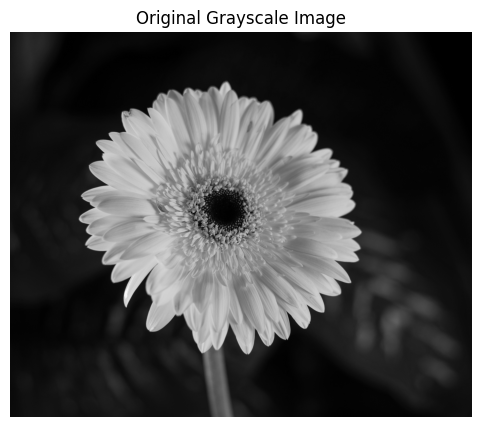

In [2]:

# Upload an image

uploaded = files.upload()

# Read uploaded image
image_name = list(uploaded.keys())[0]

img = Image.open(BytesIO(uploaded[image_name])).convert("RGB")

# Convert RGB to grayscale
gray = np.array(img.convert("L"))

print("Image uploaded successfully!")
print("Image Name:", image_name)
print("Image Shape:", gray.shape)

# Display original image
plt.figure(figsize=(6, 5))
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()


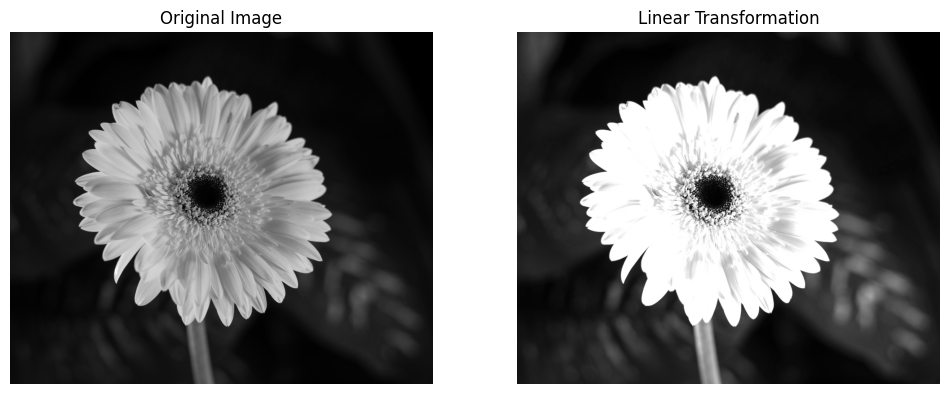

Linear Transformation completed!


In [3]:

# Task 2.1: Linear Transformation

# Set contrast and brightness
alpha = 1.5
beta = 30

# Apply linear transformation
linear_img = cv2.convertScaleAbs(
    gray, alpha=alpha, beta=beta
)

# Display original and transformed images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(linear_img, cmap="gray")
plt.title("Linear Transformation")
plt.axis("off")

plt.show()

# Save output
cv2.imwrite(
    "Assignment_2_Outputs/2.1_Linear_Transformation.png",
    linear_img
)

print("Linear Transformation completed!")


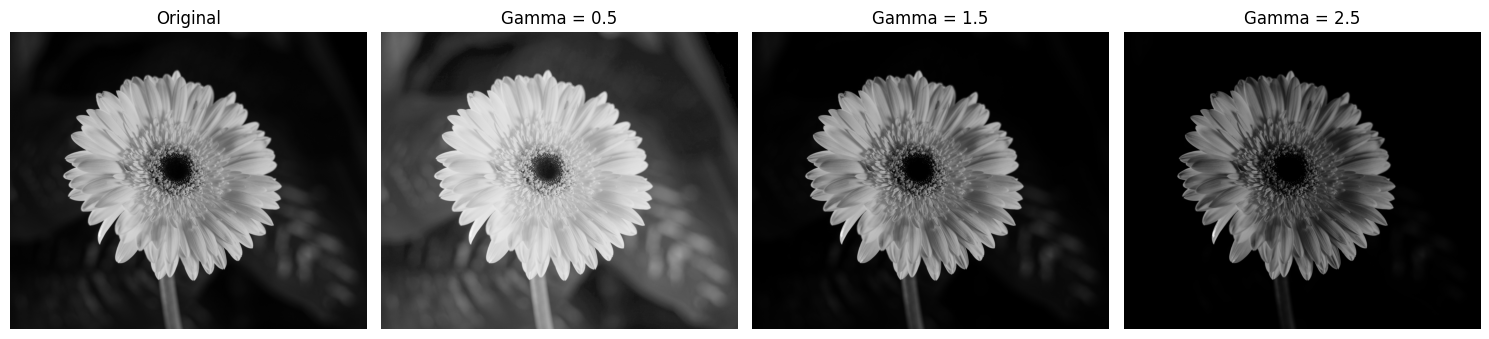

Gamma Correction completed!


In [4]:

# Task 2.2: Gamma Correction

def gamma_correction(image, gamma):
    normalized = image / 255.0
    corrected = np.power(normalized, gamma)
    return np.uint8(corrected * 255)

# Apply different gamma values
gamma_05 = gamma_correction(gray, 0.5)
gamma_15 = gamma_correction(gray, 1.5)
gamma_25 = gamma_correction(gray, 2.5)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 4, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(gamma_05, cmap="gray")
plt.title("Gamma = 0.5")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(gamma_15, cmap="gray")
plt.title("Gamma = 1.5")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(gamma_25, cmap="gray")
plt.title("Gamma = 2.5")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save outputs
cv2.imwrite("Assignment_2_Outputs/2.2_Gamma_05.png", gamma_05)
cv2.imwrite("Assignment_2_Outputs/2.2_Gamma_15.png", gamma_15)
cv2.imwrite("Assignment_2_Outputs/2.2_Gamma_25.png", gamma_25)

print("Gamma Correction completed!")


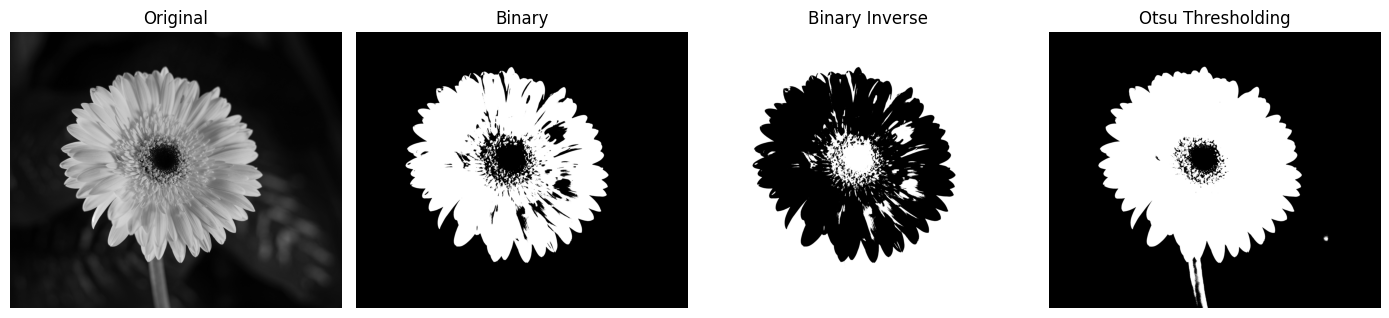

Otsu Threshold Value: 89.0
Image Thresholding completed!


In [5]:

# Task 2.3: Image Thresholding

# Set threshold value
threshold_value = 127

# Apply Binary Thresholding
_, binary = cv2.threshold(
    gray, threshold_value, 255, cv2.THRESH_BINARY
)

# Apply Binary Inverse Thresholding
_, binary_inv = cv2.threshold(
    gray, threshold_value, 255, cv2.THRESH_BINARY_INV
)

# Apply Otsu Thresholding
otsu_value, otsu = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Display results
plt.figure(figsize=(14, 5))

plt.subplot(1, 4, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(binary_inv, cmap="gray")
plt.title("Binary Inverse")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(otsu, cmap="gray")
plt.title("Otsu Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

# Print Otsu threshold
print("Otsu Threshold Value:", otsu_value)

# Save outputs
cv2.imwrite("Assignment_2_Outputs/2.3_Binary.png", binary)
cv2.imwrite("Assignment_2_Outputs/2.3_Binary_Inverse.png", binary_inv)
cv2.imwrite("Assignment_2_Outputs/2.3_Otsu.png", otsu)

print("Image Thresholding completed!")


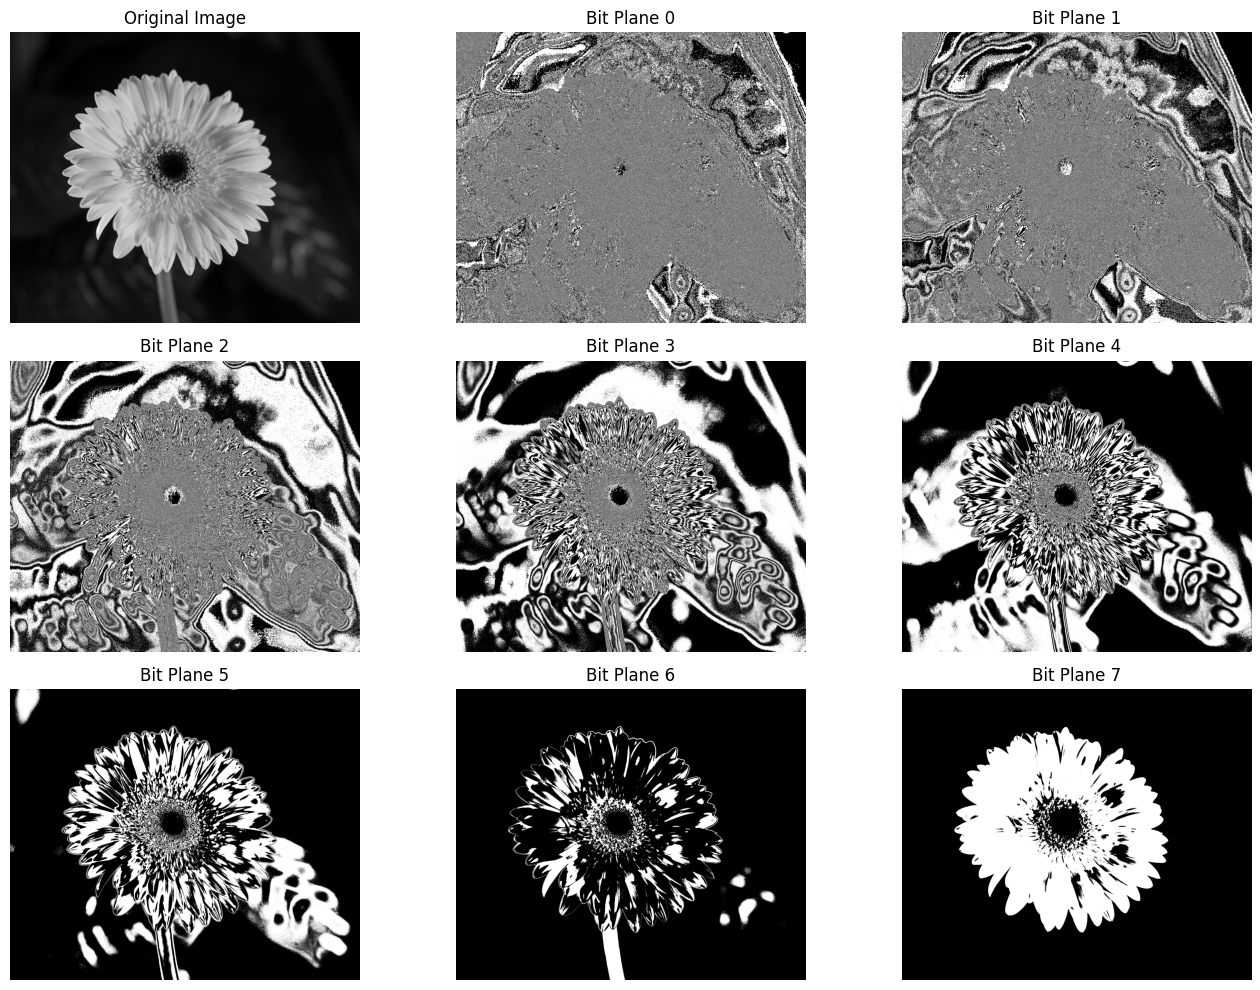

Bit Plane Slicing completed!
Total Bit Planes: 8


In [6]:

# Task 2.4: Bit Plane Slicing

# Extract 8 bit planes
bit_planes = []

for i in range(8):
    plane = (gray >> i) & 1
    plane = plane * 255
    bit_planes.append(plane)

# Display original and all bit planes
plt.figure(figsize=(14, 10))

plt.subplot(3, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Image")
plt.axis("off")

for i in range(8):
    plt.subplot(3, 3, i + 2)
    plt.imshow(bit_planes[i], cmap="gray")
    plt.title(f"Bit Plane {i}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Save all bit planes
for i in range(8):
    cv2.imwrite(
        f"Assignment_2_Outputs/2.4_Bit_Plane_{i}.png",
        bit_planes[i]
    )

print("Bit Plane Slicing completed!")
print("Total Bit Planes:", len(bit_planes))


In [7]:

# Save all assignment outputs in ZIP

import shutil

shutil.make_archive(
    "Assignment_2_Outputs",
    "zip",
    "Assignment_2_Outputs"
)

print("All outputs saved successfully!")

# Download output ZIP
files.download("Assignment_2_Outputs.zip")


All outputs saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>